# TP 2 (NLP) - Machine learning contre deep learning

**Cours NLP et Transformers - CY Tech**

On reprend la meme tache que le TP 1 (predire le locuteur d'une replique de
Tiny Shakespeare), mais on compare deux approches sur le meme protocole :

- une reference classique : TF-IDF + regression logistique ;
- un modele de deep learning : embeddings de mots + reseau recurrent (LSTM).

La comparaison n'a de sens que si le decoupage des donnees et la mesure sont
identiques pour les deux approches.

In [1]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", device)

device : cpu


## 1. Charger et preparer les donnees

On refait rapidement le travail du TP 1 : parser les repliques, garder les 5
locuteurs les plus frequents et ecarter les repliques trop courtes.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(url).read().decode("utf-8")


def parser_repliques(txt):
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

nombre_locuteurs = 5
longueur_minimale = 12
locuteurs_retenus = df["locuteur"].value_counts().head(nombre_locuteurs).index
donnees = df[df["locuteur"].isin(locuteurs_retenus)].copy()
donnees = donnees[donnees["replique"].str.split().apply(len) >= longueur_minimale]
donnees = donnees.reset_index(drop=True)

print(donnees["locuteur"].value_counts())
print(len(donnees), "exemples retenus")

locuteur
GLOUCESTER        119
DUKE VINCENTIO    113
MENENIUS          101
ROMEO              87
PETRUCHIO          83
Name: count, dtype: int64
503 exemples retenus


## 2. Decouper en train / validation / test

Le test sert une seule fois a la fin. La validation sert a suivre
l'apprentissage du modele de deep learning.

In [3]:
textes = donnees["replique"].tolist()
locuteurs = donnees["locuteur"].tolist()

# etiquettes entieres, memes pour les deux approches
classes = sorted(set(locuteurs))
classe_vers_indice = {classe: i for i, classe in enumerate(classes)}
labels = [classe_vers_indice[c] for c in locuteurs]

X_tv, X_test, y_tv, y_test = train_test_split(
    textes, labels, test_size=0.2, stratify=labels, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.2, stratify=y_tv, random_state=RANDOM_STATE
)

print(len(X_train), "train /", len(X_val), "val /", len(X_test), "test")

321 train / 81 val / 101 test


## 3. Reference classique : TF-IDF + regression logistique

On ajuste la vectorisation sur le train seulement, puis on mesure le F1 macro
sur le test. Ce score servira de point de comparaison.

In [4]:
vectoriseur = TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                              min_df=2, max_df=0.9, sublinear_tf=True)
Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

modele_ml = LogisticRegression(max_iter=1000, class_weight="balanced")
modele_ml.fit(Xtr, y_train)
pred_ml = modele_ml.predict(Xte)

f1_ml = f1_score(y_test, pred_ml, average="macro")
print("reference ML - accuracy :", round(accuracy_score(y_test, pred_ml), 3))
print("reference ML - f1 macro :", round(f1_ml, 3))

reference ML - accuracy : 0.683
reference ML - f1 macro : 0.683


## 4. Preparer les donnees pour le deep learning

Le reseau ne travaille pas sur du texte mais sur des suites d'identifiants.
On construit un vocabulaire sur le train seulement (pas de fuite), puis on
encode chaque replique en une sequence d'entiers de longueur fixe.

In [5]:
from collections import Counter

def construire_vocabulaire(textes, taille_max=5000):
    compteur = Counter()
    for texte in textes:
        compteur.update(texte.lower().split())
    vocabulaire = {"<pad>": 0, "<unk>": 1}
    for mot, _ in compteur.most_common(taille_max):
        vocabulaire[mot] = len(vocabulaire)
    return vocabulaire


def encoder_texte(texte, vocabulaire, longueur_max):
    identifiants = [vocabulaire.get(mot, 1) for mot in texte.lower().split()[:longueur_max]]
    identifiants += [0] * (longueur_max - len(identifiants))
    return identifiants


longueur_max = 40
vocabulaire = construire_vocabulaire(X_train)
print("taille du vocabulaire :", len(vocabulaire))

Xtr_ids = torch.tensor([encoder_texte(t, vocabulaire, longueur_max) for t in X_train])
Xval_ids = torch.tensor([encoder_texte(t, vocabulaire, longueur_max) for t in X_val])
Xte_ids = torch.tensor([encoder_texte(t, vocabulaire, longueur_max) for t in X_test])

ytr = torch.tensor(y_train)
yval = torch.tensor(y_val)
yte = torch.tensor(y_test)

taille du vocabulaire : 4479


In [6]:
batch_size = 32
train_loader = DataLoader(TensorDataset(Xtr_ids, ytr), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(Xval_ids, yval), batch_size=batch_size)

## 5. Definir le modele

Chaque mot devient un vecteur appris (embedding). Un LSTM parcourt la sequence
et resume le passe dans son dernier etat cache, qu'une couche lineaire projette
vers les classes.

In [7]:
class ClassifieurLSTM(nn.Module):
    def __init__(self, taille_vocabulaire, dimension_embedding, dimension_cachee, nombre_classes):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocabulaire, dimension_embedding, padding_idx=0)
        self.lstm = nn.LSTM(dimension_embedding, dimension_cachee, batch_first=True)
        self.sortie = nn.Linear(dimension_cachee, nombre_classes)

    def forward(self, sequences):
        vecteurs = self.embedding(sequences)
        _, (etat_cache, _) = self.lstm(vecteurs)
        return self.sortie(etat_cache[-1])


modele_dl = ClassifieurLSTM(
    taille_vocabulaire=len(vocabulaire),
    dimension_embedding=64,
    dimension_cachee=64,
    nombre_classes=len(classes),
).to(device)

## 6. Entrainer

Les classes sont desequilibrees : on pondere la perte par l'inverse de la
frequence de chaque classe, comme le `class_weight='balanced'` du modele ML.
On suit la perte sur train et validation a chaque epoque.

In [8]:
comptes = np.bincount(y_train, minlength=len(classes))
poids_classes = len(y_train) / (len(classes) * comptes)
poids_classes = torch.tensor(poids_classes, dtype=torch.float32, device=device)

critere = nn.CrossEntropyLoss(weight=poids_classes)
optimiseur = torch.optim.Adam(modele_dl.parameters(), lr=1e-3)
nombre_epoques = 10

historique_train = []
historique_val = []

for epoque in range(nombre_epoques):
    modele_dl.train()
    perte_cumulee = 0.0
    for sequences, cibles in train_loader:
        sequences, cibles = sequences.to(device), cibles.to(device)
        logits = modele_dl(sequences)
        perte = critere(logits, cibles)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        perte_cumulee += perte.item()

    modele_dl.eval()
    perte_val = 0.0
    with torch.no_grad():
        for sequences, cibles in val_loader:
            sequences, cibles = sequences.to(device), cibles.to(device)
            perte_val += critere(modele_dl(sequences), cibles).item()

    perte_train_moyenne = perte_cumulee / len(train_loader)
    perte_val_moyenne = perte_val / len(val_loader)
    historique_train.append(perte_train_moyenne)
    historique_val.append(perte_val_moyenne)
    print("epoque", epoque + 1,
          "| perte train", round(perte_train_moyenne, 3),
          "| perte val", round(perte_val_moyenne, 3))

epoque 1 | perte train 1.613 | perte val 1.61
epoque 2 | perte train 1.59 | perte val 1.609


epoque 3 | perte train 1.58 | perte val 1.607
epoque 4 | perte train 1.562 | perte val 1.606


epoque 5 | perte train 1.512 | perte val 1.605
epoque 6 | perte train 1.521 | perte val 1.605


epoque 7 | perte train 1.515 | perte val 1.605
epoque 8 | perte train 1.491 | perte val 1.606


epoque 9 | perte train 1.385 | perte val 1.61
epoque 10 | perte train 1.427 | perte val 1.608


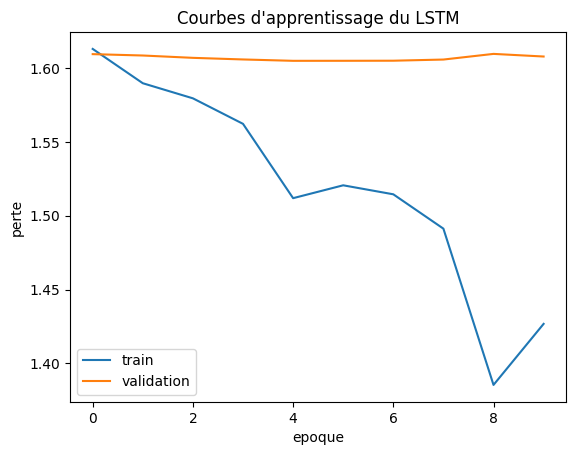

In [9]:
plt.plot(historique_train, label="train")
plt.plot(historique_val, label="validation")
plt.xlabel("epoque")
plt.ylabel("perte")
plt.title("Courbes d'apprentissage du LSTM")
plt.legend()
plt.show()

## 7. Evaluer sur le test et comparer

In [10]:
modele_dl.eval()
with torch.no_grad():
    logits_test = modele_dl(Xte_ids.to(device))
    pred_dl = logits_test.argmax(dim=1).cpu().numpy()

f1_dl = f1_score(y_test, pred_dl, average="macro")
print("deep learning - accuracy :", round(accuracy_score(y_test, pred_dl), 3))
print("deep learning - f1 macro :", round(f1_dl, 3))
print()
print("comparaison f1 macro :")
print("  TF-IDF + regression logistique :", round(f1_ml, 3))
print("  embeddings + LSTM              :", round(f1_dl, 3))

deep learning - accuracy : 0.218
deep learning - f1 macro : 0.138

comparaison f1 macro :
  TF-IDF + regression logistique : 0.683
  embeddings + LSTM              : 0.138


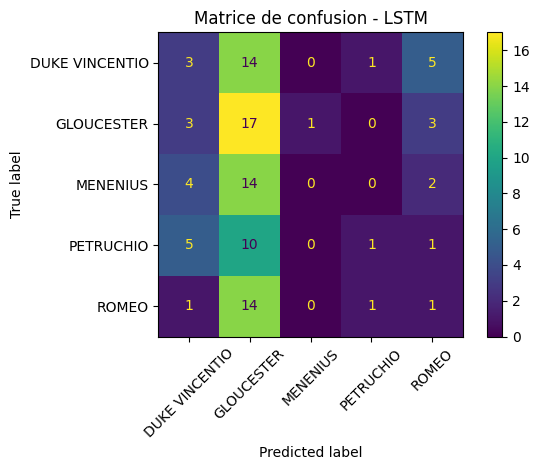

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_dl, display_labels=classes, xticks_rotation=45
)
plt.title("Matrice de confusion - LSTM")
plt.tight_layout()
plt.show()

## 8. Analyse et conclusion

- La reference TF-IDF + regression logistique l'emporte nettement : F1 macro
  0.683 contre 0.138 pour le LSTM. Sur ce jeu, le pipeline classique reste la
  meilleure approche.
- Les courbes le confirment : la perte de validation reste quasiment plate
  (autour de 1.61) pendant que la perte d'entrainement ne baisse que lentement.
  Le LSTM n'apprend donc presque rien : c'est un sous-apprentissage, pas un
  sur-apprentissage.
- La cause principale est le volume : le LSTM doit apprendre ses embeddings a
  partir de peu de repliques courtes, alors que le TF-IDF exploite directement
  des milliers de termes discriminants.
- Pistes pour aider le modele de deep learning : plus de donnees, des embeddings
  pre-entraines, un peu de regularisation (dropout) et un arret anticipe sur la
  validation.